# 06 · Multiclass classification: histological family

**Task.** Predict the histological family of the tumour from age, gender, race and the 20 mutations. The six TCGA diagnoses (`Primary_Diagnosis`) are grouped into four families (`src/config.py`, `DIAGNOSIS_FAMILY`):

| Family | TCGA diagnoses |
|---|---|
| Astrocytoma | Astrocytoma, NOS; Astrocytoma, anaplastic |
| Mixed glioma | Mixed glioma (oligoastrocytoma) |
| Oligodendroglioma | Oligodendroglioma, NOS; Oligodendroglioma, anaplastic |
| Glioblastoma | Glioblastoma |

*Why families and not the six diagnoses?* NOS and anaplastic tumours of the same family differ in grade (2 vs 3), a histological judgement that point mutations can hardly resolve. The family is the question the mutations can inform: in the TCGA lower-grade gliomas, astrocytomas tend to carry TP53/ATRX and oligodendrogliomas CIC/FUBP1 (notebook 03).

**Leakage.** `Grade` and `Project` are **not** predictors: every glioblastoma is GBM and every other family is LGG, so the grade would give the Glioblastoma class away.

**Protocol** (same as notebook 05): nested CV with 10 stratified outer folds and 3 stratified inner folds; seed 42; preprocessing inside each `Pipeline`.
- **Inner criterion and main metric: macro one-vs-one AUC** (Hand and Till): the AUC is computed for every pair of classes and averaged. It does not depend on a threshold or on the class proportions.
- **Other metrics** of the class with the highest predicted probability: accuracy, **balanced accuracy** (mean recall over the four classes; a constant prediction gives 0.25) and **macro F1**.
- **95% bootstrap intervals** stratified by class; no model is declared better if the intervals overlap; paired bootstrap of the macro-AUC difference as a complementary check.

| # | Section |
|---|---|
| 1 | Setup and target |
| 2 | Models and grids |
| 3 | Nested cross-validation |
| 4 | Model comparison |
| 5 | Confusion matrix and per-class performance |
| 6 | Consistency with the binary task |
| 7 | Comparison with the unsupervised clusters |
| 8 | Final models and permutation importance |
| 9 | Summary |

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Project root (folder containing src/config.py) not found")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

from src import config, data, evaluation as ev, models, plotting, reporting, unsupervised as uns
from src.pipelines import format_value
from src.plotting import NEUTRAL

plotting.set_style()
pd.set_option("display.precision", 3)

df = data.load_processed()
FEATURES = data.feature_columns("classification")
assert not set(FEATURES) & set(config.LEAKAGE_COLS + ["Grade"]), "Leakage column among the predictors"
X = df[FEATURES]
y = data.diagnosis_family(df)
LABELS = [config.MULTICLASS_LABELS[k] for k in range(len(config.MULTICLASS_LABELS))]
counts = pd.crosstab(df[config.MULTICLASS_TARGET], pd.Series([LABELS[k] for k in y], name="Family", index=df.index))
display(counts)
sizes = pd.Series(np.bincount(y), index=LABELS)
results = {"features": FEATURES, "n": len(y), "class_sizes": sizes.to_dict(),
           "diagnosis_to_family": config.DIAGNOSIS_FAMILY}
print(f"{len(y)} patients, {len(FEATURES)} predictors; class sizes:", sizes.to_dict())
reporting.save_table_tex(pd.DataFrame({"Family": LABELS, "TCGA diagnoses": [", ".join(d for d, f in config.DIAGNOSIS_FAMILY.items() if f == l) for l in LABELS],
                                       "Patients": sizes.values}), "mc_classes", column_format="lp{8cm}r")

Family,Astrocytoma,Glioblastoma,Mixed glioma,Oligodendroglioma
Primary_Diagnosis,,,,
"Astrocytoma, NOS",56,0,0,0
"Astrocytoma, anaplastic",127,0,0,0
Glioblastoma,0,352,0,0
Mixed glioma,0,0,127,0
"Oligodendroglioma, NOS",0,0,0,104
"Oligodendroglioma, anaplastic",0,0,0,73


839 patients, 23 predictors; class sizes: {'Astrocytoma': 183, 'Mixed glioma': 127, 'Oligodendroglioma': 177, 'Glioblastoma': 352}


WindowsPath('C:/Users/ori/ML/results/tables/mc_classes.tex')

## 2. Models and hyperparameter grids

The binary model families that extend directly to K classes, with the same grids: **multinomial logistic regression** (one coefficient vector per class and a softmax link, L1 or L2 penalty; `saga` solver, which supports both penalties for the multinomial model), a **pruned tree**, a **random forest** and **XGBoost** (one tree per class at every boosting round). Naive Bayes (the worst-calibrated binary model) and the SVM (one model per pair of classes with Platt probabilities, much more costly in nested CV) are not repeated.

In [2]:
MODELS = models.multiclass_models(FEATURES)

def describe_grid(grid):
    return ", ".join(f"{k.split('__', 1)[1]} in [{', '.join(format_value(x) for x in v)}]" for k, v in grid.items()) or "none"

grids = pd.DataFrame([{"Model": n, "Hyperparameters searched": describe_grid(g),
                       "Configurations": int(np.prod([len(v) for v in g.values()])) if g else 1}
                      for n, (p, g) in MODELS.items()])
with pd.option_context("display.max_colwidth", None):
    display(grids)
reporting.save_table_tex(grids, "mc_models_grids", column_format="lp{10.5cm}r")

,Model,Hyperparameters searched,Configurations
0,Prior baseline,none,1
1,Logistic regression,"penalty in [l1, l2], C in [0.001, 0.003162, 0.01, 0.03162, 0.1, 0.3162, 1, 3.162, 10, 31.62, 100]",22
2,Decision tree (pruned),"ccp_alpha in [0, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05], criterion in [gini, entropy]",14
3,Random forest,"max_features in [sqrt, 0.33, 0.66], min_samples_leaf in [1, 5, 10, 20]",12
4,XGBoost,"n_estimators in [100, 300], learning_rate in [0.03, 0.1], max_depth in [2, 3, 5]",12


WindowsPath('C:/Users/ori/ML/results/tables/mc_models_grids.tex')

## 3. Nested cross-validation

A few minutes. Permutation importance (drop in macro AUC when a predictor is shuffled) is computed on every outer test fold.

In [3]:
NESTED = {}
t0 = time.time()
for name, (pipe, grid) in MODELS.items():
    t = time.time()
    NESTED[name] = ev.nested_cv(pipe, grid, X, y, task="multiclass", scoring=ev.MULTICLASS_SCORING,
                                metric_fn=ev.multiclass_metrics, importance=(name != "Prior baseline"))
    m = ev.multiclass_metrics(y, NESTED[name]["oof"])
    print(f"{name:<24} macro AUC = {m['Macro AUC']:.3f}  bal. acc = {m['Balanced accuracy']:.3f}  "
          f"macro F1 = {m['Macro F1']:.3f}   ({time.time() - t:.0f} s)")
print(f"Total: {time.time() - t0:.0f} s")
oof = pd.DataFrame({"Case_ID": df[config.ID_COL], "Family": y})
for n, r in NESTED.items():
    for k, lab in enumerate(LABELS):
        oof[f"{n} | P({lab})"] = r["oof"][:, k]
oof.to_csv(config.LOGS / "06_multiclass_oof_probabilities.csv", index=False)

Prior baseline           macro AUC = 0.492  bal. acc = 0.250  macro F1 = 0.148   (0 s)


Logistic regression      macro AUC = 0.779  bal. acc = 0.554  macro F1 = 0.523   (35 s)


Decision tree (pruned)   macro AUC = 0.760  bal. acc = 0.566  macro F1 = 0.527   (15 s)


Random forest            macro AUC = 0.779  bal. acc = 0.567  macro F1 = 0.525   (72 s)


XGBoost                  macro AUC = 0.774  bal. acc = 0.560  macro F1 = 0.538   (28 s)
Total: 151 s


## 4. Model comparison

,Model,Macro AUC,Macro AUC CI low,Macro AUC CI high,Balanced accuracy,Balanced accuracy CI low,Balanced accuracy CI high,Macro F1,Macro F1 CI low,Macro F1 CI high,Accuracy,Accuracy CI low,Accuracy CI high
0,Prior baseline,0.492,0.470,0.516,0.250,0.250,0.250,0.148,0.148,0.148,0.420,0.420,0.420
1,Logistic regression,0.779,0.760,0.799,0.554,0.528,0.581,0.523,0.498,0.547,0.665,0.640,0.690
2,Decision tree (pruned),0.760,0.741,0.780,0.566,0.542,0.592,0.527,0.504,0.550,0.675,0.651,0.698
3,Random forest,0.779,0.761,0.799,0.567,0.544,0.592,0.525,0.504,0.547,0.677,0.653,0.701
4,XGBoost,0.774,0.756,0.794,0.560,0.534,0.589,0.538,0.510,0.567,0.667,0.644,0.692


Highest macro AUC: Random forest; overlapping: ['Logistic regression', 'Decision tree (pruned)', 'XGBoost']
Highest balanced accuracy: Random forest; overlapping: ['Logistic regression', 'Decision tree (pruned)', 'XGBoost']


,Model,Macro AUC - Random forest,CI low,CI high
0,Logistic regression,-6.583e-04,-0.011,0.009
1,Decision tree (pruned),-1.916e-02,-0.031,-0.006
2,XGBoost,-5.246e-03,-0.015,0.005


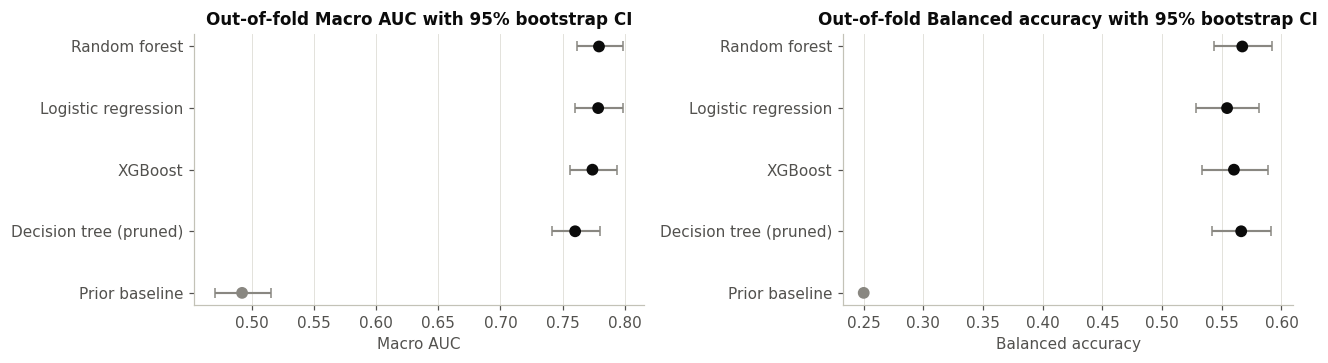

In [4]:
METRICS = ["Macro AUC", "Balanced accuracy", "Macro F1", "Accuracy"]
rows = []
for name, r in NESTED.items():
    cis = ev.metric_cis(y, r["oof"], ev.multiclass_metrics, stratify=y)
    row = {"Model": name}
    for metric in METRICS:
        point, lo, hi = cis[metric]
        row.update({metric: point, f"{metric} CI low": lo, f"{metric} CI high": hi,
                    f"{metric} fold mean": r["folds"][metric].mean(), f"{metric} fold SD": r["folds"][metric].std()})
    rows.append(row)
summary = pd.DataFrame(rows)
display(summary[["Model"] + [c for m in METRICS for c in (m, f"{m} CI low", f"{m} CI high")]])
results["summary"] = summary.to_dict(orient="records")

best, ties = ev.best_and_ties(summary, "Macro AUC", lower_is_better=False)
best_bacc, ties_bacc = ev.best_and_ties(summary, "Balanced accuracy", lower_is_better=False)
print(f"Highest macro AUC: {best}; overlapping: {ties}")
print(f"Highest balanced accuracy: {best_bacc}; overlapping: {ties_bacc}")
results.update({"best": best, "ties": ties, "best_bacc": best_bacc, "ties_bacc": ties_bacc})

S = summary.set_index("Model")
ci = lambda m, k, d=3: f"{S.loc[m, k]:.{d}f} [{S.loc[m, k + ' CI low']:.{d}f}, {S.loc[m, k + ' CI high']:.{d}f}]"
reporting.save_table_tex(pd.DataFrame({"Model": summary["Model"], **{k: [ci(m, k) for m in summary["Model"]] for k in METRICS}}),
                         "mc_model_comparison", column_format="lllll")

paired = []
for name, r in NESTED.items():
    if name in ("Prior baseline", best):
        continue
    d = ev.paired_difference_ci(y, r["oof"], NESTED[best]["oof"], ev.multiclass_auc, stratify=y)
    paired.append({"Model": name, f"Macro AUC - {best}": d[0], "CI low": d[1], "CI high": d[2]})
paired = pd.DataFrame(paired)
display(paired)
results["paired_differences"] = paired.to_dict(orient="records")
reporting.save_table_tex(pd.DataFrame({"Model": paired["Model"],
                                       f"Macro AUC difference vs {best}": [f"{a:+.3f} [{b:+.3f}, {c:+.3f}]" for a, b, c in paired.iloc[:, 1:4].values]}),
                         "mc_paired_differences", column_format="ll")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
order = summary.sort_values("Macro AUC")["Model"].tolist()
s = S.loc[order]
for ax, metric in ((axes[0], "Macro AUC"), (axes[1], "Balanced accuracy")):
    err = np.clip([s[metric] - s[f"{metric} CI low"], s[f"{metric} CI high"] - s[metric]], 0, None)
    ax.errorbar(s[metric], np.arange(len(order)), xerr=err, fmt="none", ecolor=NEUTRAL, elinewidth=1.4, capsize=3)
    ax.scatter(s[metric], np.arange(len(order)), color=[NEUTRAL if "baseline" in m else plotting.INK for m in order], s=45, zorder=3)
    ax.set_yticks(np.arange(len(order)), order); ax.grid(axis="y", visible=False)
    ax.set_title(f"Out-of-fold {metric} with 95% bootstrap CI"); ax.set_xlabel(metric)
fig.tight_layout()
plotting.save_figure(fig, "mc_model_comparison")
plt.show()

## 5. Confusion matrix and per-class performance

Rows: true family; columns: family with the highest predicted probability; each row is normalised to 1 (the diagonal is the recall of that family). The astrocytomas predicted as glioblastoma are checked for their IDH status. The per-class one-vs-rest AUC measures how well P(family) ranks the patients of that family above all others.

Predicted,Astrocytoma,Mixed glioma,Oligodendroglioma,Glioblastoma
True,,,,
Astrocytoma,118,0,11,54
Mixed glioma,71,0,40,16
Oligodendroglioma,33,1,123,20
Glioblastoma,23,0,2,327


,Patients,Recall,Precision,One-vs-rest AUC,One-vs-rest AUC CI
Astrocytoma,183,0.645,0.482,0.763,"[0.726, 0.797]"
Mixed glioma,127,0.000,0.000,0.722,"[0.683, 0.760]"
Oligodendroglioma,177,0.695,0.699,0.861,"[0.827, 0.896]"
Glioblastoma,352,0.929,0.784,0.917,"[0.896, 0.936]"


Mixed glioma patients predicted as: {'Astrocytoma': 0.559, 'Mixed glioma': 0.0, 'Oligodendroglioma': 0.315, 'Glioblastoma': 0.126}
Astrocytomas predicted as glioblastoma: {'n': 54, 'idh_wildtype': 53, 'astro_idh_wildtype_total': 53}


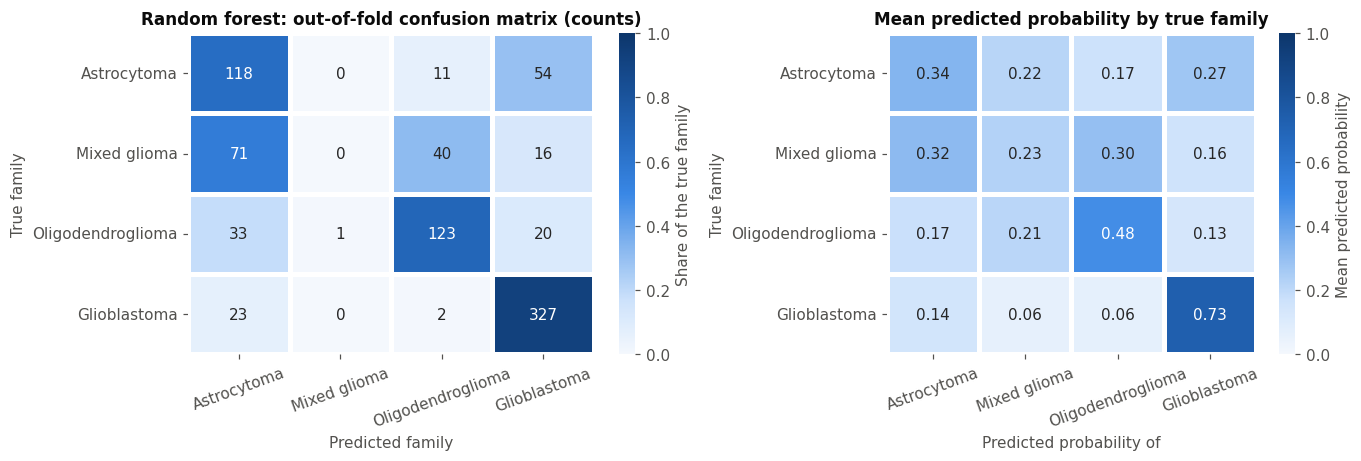

In [5]:
from src.evaluation import auc_score
P_best = NESTED[best]["oof"]
pred = P_best.argmax(axis=1)
cm = pd.crosstab(pd.Series([LABELS[k] for k in y], name="True"), pd.Series([LABELS[k] for k in pred], name="Predicted")).reindex(index=LABELS, columns=LABELS, fill_value=0)
cm_row = cm.div(cm.sum(axis=1), axis=0)
display(cm)
per_class = pd.DataFrame({"Patients": sizes.values,
                          "Recall": np.diag(cm_row.values),
                          "Precision": np.diag(cm.values) / np.maximum(cm.sum(axis=0).values, 1),
                          "One-vs-rest AUC": [auc_score((y == k).astype(int), P_best[:, k]) for k in range(len(LABELS))]},
                         index=LABELS)
per_class["One-vs-rest AUC CI"] = [
    "[{:.3f}, {:.3f}]".format(*ev.bootstrap_ci(lambda t, p, k=k: auc_score((t == k).astype(int), p[:, k]), y, P_best, stratify=y)[1:])
    for k in range(len(LABELS))]
display(per_class)
results["confusion_matrix_best"] = cm.to_dict(orient="index")
results["per_class_best"] = per_class.to_dict(orient="index")
mixed = cm_row.loc["Mixed glioma"]
results["mixed_predicted_as"] = mixed.to_dict()
print("Mixed glioma patients predicted as:", mixed.round(3).to_dict())
# Astrocytomas predicted as glioblastoma: what is their IDH status?
idh_mut = ((df["IDH1"] == 1) | (df["IDH2"] == 1)).values
astro, gbm_k = LABELS.index("Astrocytoma"), LABELS.index("Glioblastoma")
a2g = (y == astro) & (pred == gbm_k)
results["astro_as_gbm"] = {"n": int(a2g.sum()), "idh_wildtype": int((a2g & ~idh_mut).sum()),
                           "astro_idh_wildtype_total": int(((y == astro) & ~idh_mut).sum())}
print("Astrocytomas predicted as glioblastoma:", results["astro_as_gbm"])
reporting.save_table_tex(per_class.rename_axis("Family").reset_index(), "mc_per_class", float_format="{:.3f}", column_format="lrrrrl")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(cm_row, annot=cm.values, fmt="d", cmap=plotting.SEQUENTIAL, vmin=0, vmax=1, cbar_kws={"label": "Share of the true family"},
            linewidths=2, linecolor="white", ax=axes[0])
axes[0].set_title(f"{best}: out-of-fold confusion matrix (counts)"); axes[0].set_xlabel("Predicted family"); axes[0].set_ylabel("True family")
axes[0].tick_params(axis="x", rotation=20)
# Mean predicted probability of each family, by true family: where the uncertainty lies
mean_p = pd.DataFrame(P_best, columns=LABELS).groupby(np.array([LABELS[k] for k in y])).mean().reindex(LABELS)
sns.heatmap(mean_p, annot=True, fmt=".2f", cmap=plotting.SEQUENTIAL, vmin=0, vmax=1, cbar_kws={"label": "Mean predicted probability"},
            linewidths=2, linecolor="white", ax=axes[1])
axes[1].set_title("Mean predicted probability by true family"); axes[1].set_xlabel("Predicted probability of"); axes[1].set_ylabel("True family")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
plotting.save_figure(fig, "mc_confusion")
plt.show()
results["mean_probability_by_family"] = mean_p.to_dict(orient="index")

## 6. Consistency with the binary task

The probability of the Glioblastoma class is, by construction, a probability of GBM. Its AUC for the binary grade, computed on the same out-of-fold predictions, should be close to the AUC of the binary models of notebook 05: the extra classes should not have degraded the grade information.

In [6]:
grade = df["Grade"].values
gbm_k = LABELS.index("Glioblastoma")
binary_from_mc = {n: ev.bootstrap_ci(lambda t, p: auc_score(t, p[:, gbm_k]), grade, r["oof"], stratify=grade)
                  for n, r in NESTED.items() if n != "Prior baseline"}
tab = pd.DataFrame(binary_from_mc, index=["AUC for the grade", "CI low", "CI high"]).T
display(tab)
results["grade_auc_from_multiclass"] = tab.to_dict(orient="index")

,AUC for the grade,CI low,CI high
Logistic regression,0.909,0.888,0.929
Decision tree (pruned),0.889,0.867,0.911
Random forest,0.917,0.897,0.935
XGBoost,0.910,0.891,0.929


## 7. Comparison with the unsupervised clusters

Notebook 03 found, without labels, a secondary k-means solution with three clusters: an IDH-wildtype cluster and two IDH-mutant ones (TP53/ATRX and CIC/FUBP1). The same clustering is recomputed here (same function, data and seed) and cross-tabulated with the families, which were not used to build it.

In [7]:
GENES = data.feature_columns("unsupervised")
km = uns.kmeans_labels(df[GENES].values, 3)
clusters = uns.order_clusters(km.labels_, grade)
xt = pd.crosstab(pd.Series(clusters, name="Cluster (k = 3)"), pd.Series([LABELS[k] for k in y], name="Family")).reindex(columns=LABELS)
display(xt)
display(xt.div(xt.sum(axis=1), axis=0).round(3))
ari_family = adjusted_rand_score(y, clusters)
ari_grade = adjusted_rand_score(grade, clusters)
lgg = grade == 0
ari_lgg = adjusted_rand_score(y[lgg], clusters[lgg])
print(f"ARI clusters vs family = {ari_family:.3f} (vs grade = {ari_grade:.3f}); among LGG only, clusters vs family = {ari_lgg:.3f}")
results["clusters_vs_family"] = {"table": xt.to_dict(orient="index"), "ARI family": ari_family, "ARI grade": ari_grade,
                                 "ARI family LGG only": ari_lgg, "cluster sizes": pd.Series(clusters).value_counts().sort_index().to_dict()}
reporting.save_table_tex(xt.rename_axis("Cluster").reset_index(), "mc_clusters_vs_family", float_format="{:.0f}", column_format="lrrrr")

Family,Astrocytoma,Mixed glioma,Oligodendroglioma,Glioblastoma
Cluster (k = 3),,,,
C1,51,17,22,324
C2,122,73,39,28
C3,10,37,116,0


Family,Astrocytoma,Mixed glioma,Oligodendroglioma,Glioblastoma
Cluster (k = 3),,,,
C1,0.123,0.041,0.053,0.783
C2,0.466,0.279,0.149,0.107
C3,0.061,0.227,0.712,0.000


ARI clusters vs family = 0.430 (vs grade = 0.329); among LGG only, clusters vs family = 0.171


WindowsPath('C:/Users/ori/ML/results/tables/mc_clusters_vs_family.tex')

## 8. Final models and permutation importance

Final models: the same tuning procedure applied to all patients. Permutation importance: drop in macro AUC on the outer test folds (mean over the 10 folds).

,Model,Hyperparameter,Values chosen in the 10 outer folds,Final model (all data)
0,Logistic regression,penalty,"l2 (6), l1 (4)",l2
1,Logistic regression,C,"0.03162 (4), 0.1 (3), 0.3162 (2), 0.01 (1)",0.3162
2,Decision tree (pruned),ccp_alpha,"0.02 (6), 0.005 (4)",0.02
3,Decision tree (pruned),criterion,"entropy (6), gini (4)",entropy
4,Random forest,max_features,"sqrt (7), 0.33 (2), 0.66 (1)",sqrt
5,Random forest,min_samples_leaf,"5 (9), 10 (1)",5
6,XGBoost,n_estimators,"100 (8), 300 (2)",300
7,XGBoost,learning_rate,"0.03 (8), 0.1 (2)",0.03
8,XGBoost,max_depth,"2 (5), 3 (4), 5 (1)",2


,Model,Best inner score,5th best inner score,Configurations within 0.005 of the best,Configurations
0,Logistic regression,0.786,0.786,16,22
1,Decision tree (pruned),0.773,0.759,1,14
2,Random forest,0.792,0.784,3,12
3,XGBoost,0.784,0.779,5,12


,Logistic regression,Random forest,XGBoost
IDH1,1.084e-01,1.141e-01,1.447e-01
CIC,2.476e-02,2.156e-02,2.847e-02
Age_at_diagnosis,1.134e-02,1.009e-02,1.828e-02
IDH2,9.752e-03,9.920e-03,1.147e-02
TP53,5.078e-03,1.565e-02,9.818e-03
PTEN,2.647e-03,2.904e-03,4.439e-03
NOTCH1,4.640e-03,8.481e-04,2.540e-03
ATRX,8.328e-04,4.413e-03,-5.439e-05
FAT4,2.843e-03,-6.765e-05,1.911e-03
PIK3CA,1.369e-03,1.019e-03,1.664e-03


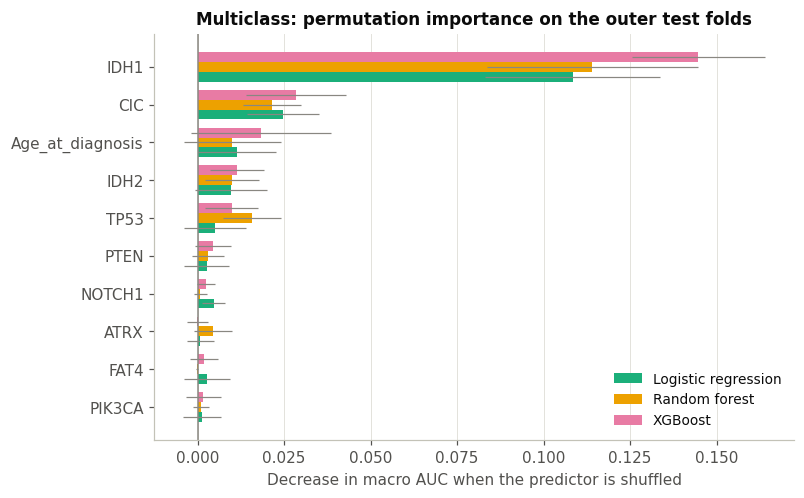

In [8]:
FINAL, SEARCH, hp_rows = {}, {}, []
for name, (pipe, grid) in MODELS.items():
    m_, p_, SEARCH[name] = ev.fit_final(pipe, grid, X, y, "multiclass", ev.MULTICLASS_SCORING, return_search=True)
    FINAL[name] = (m_, p_)
    if not grid:
        continue
    folds = NESTED[name]["folds"]
    for p in [k.split("__", 1)[1] for k in grid]:
        c = folds[p].map(format_value).value_counts()
        hp_rows.append({"Model": name, "Hyperparameter": p,
                        "Values chosen in the 10 outer folds": ", ".join(f"{v} ({n})" for v, n in c.items()),
                        "Final model (all data)": format_value(p_[p])})
hp = pd.DataFrame(hp_rows)
with pd.option_context("display.max_colwidth", None):
    display(hp)
reporting.save_table_tex(hp, "mc_hyperparameters", column_format="llp{7cm}l")
results["final_hyperparameters"] = {n: p for n, (m, p) in FINAL.items()}
flat = pd.DataFrame([{"Model": n, **ev.search_flatness(s, 0.005)} for n, s in SEARCH.items() if s is not None])
display(flat)
results["final_search_flatness"] = flat.to_dict(orient="records")

imp_models = [m for m in MODELS if m not in ("Prior baseline", "Decision tree (pruned)")]
imp = pd.DataFrame({m: NESTED[m]["importance"].mean() for m in imp_models})
imp_sd = pd.DataFrame({m: NESTED[m]["importance"].std() for m in imp_models})
imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]
display(imp.head(10))
results["permutation_importance_mean"] = imp.to_dict(orient="index")
reporting.save_table_tex(imp.head(10).rename_axis("Predictor").reset_index(), "mc_permutation_importance", float_format="{:.3f}")

top = imp.index[:10][::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
h = 0.26
for i, m in enumerate(imp_models):
    ax.barh(np.arange(len(top)) + (i - 1) * h, imp.loc[top, m], xerr=imp_sd.loc[top, m], height=h,
            color=plotting.CATEGORICAL[i + 2], label=m, error_kw=dict(ecolor=NEUTRAL, lw=0.8))
ax.set_yticks(np.arange(len(top)), top); ax.axvline(0, color=NEUTRAL, lw=1)
ax.set_xlabel("Decrease in macro AUC when the predictor is shuffled")
ax.set_title("Multiclass: permutation importance on the outer test folds")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
plotting.save_figure(fig, "mc_permutation_importance")
plt.show()

## 9. Summary

Generated from the results above; saved in `results/logs/06_multiclass.json`.

In [9]:
rows_ = [
    ("Classes", ", ".join(f"{k} ({v})" for k, v in sizes.items())),
    ("Prior baseline", f"macro AUC {ci('Prior baseline', 'Macro AUC')}, balanced accuracy {ci('Prior baseline', 'Balanced accuracy')}"),
    ("Highest macro AUC", f"{best}: macro AUC {ci(best, 'Macro AUC')}, balanced accuracy {ci(best, 'Balanced accuracy')}, macro F1 {ci(best, 'Macro F1')}"),
    ("Models tied with it (overlapping intervals)", ", ".join(ties) if ties else "none"),
    ("Recall per family (best model)", ", ".join(f"{k} {v:.2f}" for k, v in per_class["Recall"].items())),
    ("Mixed glioma predicted as", ", ".join(f"{k} {v:.2f}" for k, v in mixed.items())),
    ("Clusters (k = 3) vs family", f"ARI {ari_family:.3f}; among LGG only {ari_lgg:.3f}"),
    ("Most important predictors (permutation)", ", ".join(f"{i} ({v:.3f})" for i, v in imp.mean(axis=1).head(4).items())),
]
final_summary = pd.DataFrame(rows_, columns=["Topic", "Finding"])
with pd.option_context("display.max_colwidth", None):
    display(final_summary)
results["findings"] = dict(rows_)
for name, r in NESTED.items():
    results.setdefault("folds", {})[name] = r["folds"].to_dict(orient="records")
path = reporting.save_json(results, "06_multiclass")
print("Saved", path.relative_to(config.ROOT))

,Topic,Finding
0,Classes,"Astrocytoma (183), Mixed glioma (127), Oligodendroglioma (177), Glioblastoma (352)"
1,Prior baseline,"macro AUC 0.492 [0.470, 0.516], balanced accuracy 0.250 [0.250, 0.250]"
2,Highest macro AUC,"Random forest: macro AUC 0.779 [0.761, 0.799], balanced accuracy 0.567 [0.544, 0.592], macro F1 0.525 [0.504, 0.547]"
3,Models tied with it (overlapping intervals),"Logistic regression, Decision tree (pruned), XGBoost"
4,Recall per family (best model),"Astrocytoma 0.64, Mixed glioma 0.00, Oligodendroglioma 0.69, Glioblastoma 0.93"
5,Mixed glioma predicted as,"Astrocytoma 0.56, Mixed glioma 0.00, Oligodendroglioma 0.31, Glioblastoma 0.13"
6,Clusters (k = 3) vs family,ARI 0.430; among LGG only 0.171
7,Most important predictors (permutation),"IDH1 (0.122), CIC (0.025), Age_at_diagnosis (0.013), IDH2 (0.010)"


Saved results\logs\06_multiclass.json
